# 06 — Benchmark Externo Zero-Shot

Evaluación fuera de dominio contra 6 datasets públicos.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from discurso_odio.config import load_settings
from discurso_odio.data.loaders import load_all_splits, load_split, get_class_weights
from discurso_odio.paths import REPORTS_FIGURES, REPORTS_METRICS
from discurso_odio.utils.plotting import setup_plot_style, get_label_names, get_class_palette
from discurso_odio.utils.seed import set_seed

settings = load_settings()
set_seed(settings['project']['seed'])
setup_plot_style()
LABELS = get_label_names()
REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)
REPORTS_METRICS.mkdir(parents=True, exist_ok=True)
print('Proyecto:', settings['project']['name'])

from discurso_odio.evaluation.benchmark import run_benchmark
from discurso_odio.paths import MODELS_DIR



Proyecto: discurso-odio-sv


In [2]:
model_dir = MODELS_DIR / 'mbert-sv'
assert model_dir.exists(), 'Entrene mBERT primero (notebook 04)'
results = run_benchmark(str(model_dir))
results


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,dataset,n_samples,status,f1_macro,f1_binary,accuracy,accuracy_binary
0,piuba-bigdata/contextualized_hate_speech,1614,ok,0.312712,0.711000,0.350062,0.641884
1,gplsi/SocialTOX,968,ok,0.265848,0.580184,0.414256,0.575413
2,antonn-dromundo/SinOdio-LATAM-Regional-HateSpeech,2000,ok,0.139423,0.317146,0.269000,0.311000
3,textdetox/multilingual_toxicity_dataset,2000,ok,0.269293,0.702335,0.445000,0.649500
4,SINAI/ALIA-es-discriminative-hate-speech,3000,ok,0.240854,0.382630,0.426333,0.497667
5,Gerard-1705/exist_dataset_es,1500,ok,0.171576,0.565491,0.293333,0.540000


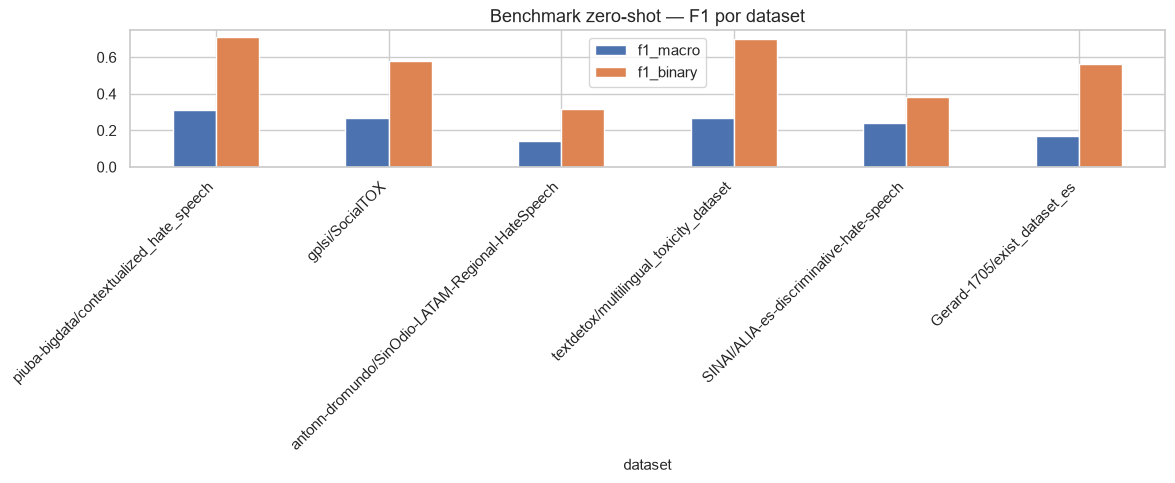

Resultados exportados.


In [3]:
results.to_csv(REPORTS_METRICS / 'benchmark_externo.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 5))
plot_data = results[results['status']=='ok']
if len(plot_data):
    plot_data.plot(x='dataset', y=['f1_macro', 'f1_binary'], kind='bar', ax=ax)
    ax.set_title('Benchmark zero-shot — F1 por dataset')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(REPORTS_FIGURES / '05_benchmark_externo.png')
    plt.show()
print('Resultados exportados.')
